# Forecasting Contact-Centre Demand & Staffing (Erlang C)

**Context (simulated case study).** The companion Power BI report showed the contact centre missed its 80/20 service level on **Sundays (63%)** and during **Ramadan (43%)**, because shifts were planned for an "average day".
The operations manager asks:
1. How many contacts should we expect each day of **January 2026** and **Ramadan 2026**?
2. Which forecasting method is accurate enough to plan with?
3. How many agents do we need **per hour** to reach 80% of calls answered within 20 seconds?

**Approach:** daily time series of 2025 → compare three models on a hold-out period (Nov-Dec 2025) → refit the best model → split the daily forecast into hours → **Erlang C** to convert volume into required agents.

In [1]:
import json, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette=["#1F4E79", "#F39C12", "#27AE60", "#C0392B"])
plt.rcParams["figure.dpi"] = 110
R = {}
calls = pd.read_csv("data/calls_2025.csv").drop_duplicates("CallID")
calls["ts"] = pd.to_datetime(calls.CallDateTime)
calls["Handle"] = pd.to_numeric(calls.TalkSeconds.astype(str).str.split(":").apply(
    lambda p: int(p[0]) * 60 + int(p[1]) if len(p) == 2 else float(p[0]))) + calls.HoldSeconds + calls.ACWSeconds
y = calls.set_index("ts").resample("D").size().rename("calls")
R.update(days=len(y), total_calls=int(y.sum()), mean_daily=round(y.mean(), 1))
print(f"{len(y)} days, {y.sum():,} contacts, mean {y.mean():.0f}/day")

365 days, 154,325 contacts, mean 423/day


## 1. What does the series look like?
Calendar effects matter in Saudi Arabia: the working week starts on **Sunday**, **Friday** is the weekend, **Ramadan** (1-29 Mar 2025) shifts demand, and bills are issued at the **start of each month**.

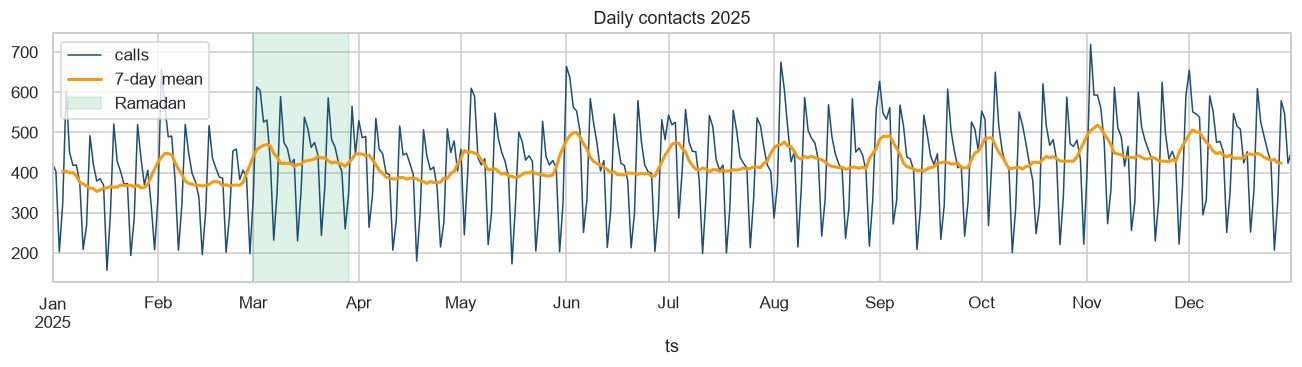

ts
Sunday       570.0
Monday       504.0
Tuesday      461.0
Wednesday    444.0
Thursday     424.0
Friday       226.0
Saturday     331.0
Name: calls, dtype: float64
billing days (1-5) uplift: +20.7%


In [2]:
cal = pd.DataFrame(index=y.index)
cal["ramadan"] = ((cal.index >= "2025-03-01") & (cal.index <= "2025-03-29")).astype(int)
cal["billing_days"] = (cal.index.day <= 5).astype(int)
fig, ax = plt.subplots(figsize=(12, 3.5))
y.plot(ax=ax, color="#1F4E79", lw=1); y.rolling(7, center=True).mean().plot(ax=ax, color="#F39C12", lw=2, label="7-day mean")
ax.axvspan("2025-03-01", "2025-03-29", color="#27AE60", alpha=0.15, label="Ramadan"); ax.legend(); ax.set_title("Daily contacts 2025")
plt.tight_layout(); plt.savefig("figures/01_series.png"); plt.show()
wd = y.groupby(y.index.day_name()).mean().reindex(["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"])
R["mean_by_weekday"] = wd.round(1).to_dict()
R["billing_uplift"] = round(y[cal.billing_days == 1].mean() / y[cal.billing_days == 0].mean() - 1, 4)
print(wd.round(0)); print(f"billing days (1-5) uplift: {R['billing_uplift']:+.1%}")

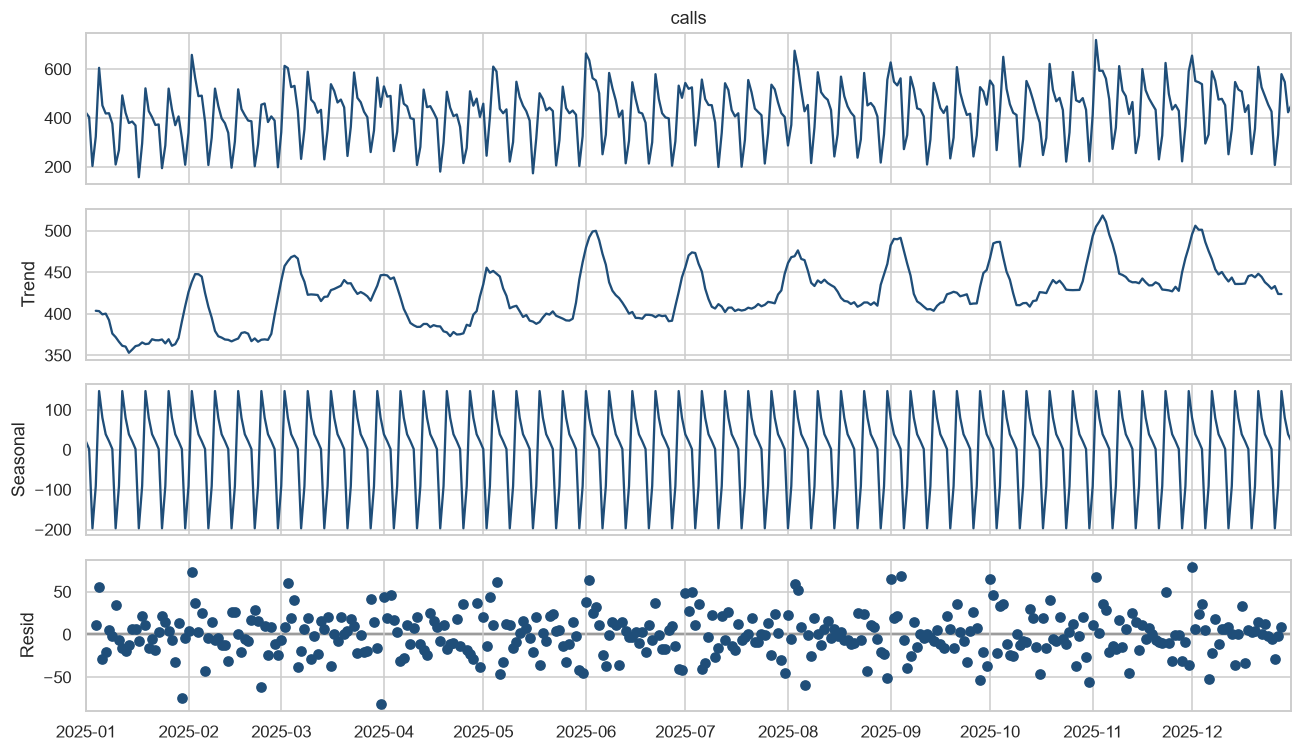

In [3]:
dec = seasonal_decompose(y, period=7, model="additive")
fig = dec.plot(); fig.set_size_inches(12, 7); plt.tight_layout(); plt.savefig("figures/02_decomposition.png"); plt.show()

## 2. Model comparison on a hold-out period
Train on **Jan-Oct 2025**, test on **Nov-Dec 2025** (61 days the models never saw).

| Model | Idea |
|---|---|
| Seasonal naive | same weekday last week (the benchmark to beat) |
| Holt-Winters | level + trend + weekly seasonality (exponential smoothing) |
| SARIMAX | ARIMA with weekly seasonality + calendar regressors (billing days, Ramadan) |

In [4]:
split = "2025-10-31"
y_tr, y_te = y[:split], y["2025-11-01":]
X_tr, X_te = cal.loc[y_tr.index, ["billing_days", "ramadan"]], cal.loc[y_te.index, ["billing_days", "ramadan"]]
f_naive = y.shift(7).loc[y_te.index]
hw = ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=7).fit()
f_hw = hw.forecast(len(y_te)); f_hw.index = y_te.index
sar = SARIMAX(y_tr, exog=X_tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
f_sar = sar.get_forecast(len(y_te), exog=X_te).predicted_mean; f_sar.index = y_te.index

def scores(f):
    e = y_te - f
    return {"MAE": round(e.abs().mean(), 1), "RMSE": round(np.sqrt((e ** 2).mean()), 1), "MAPE": round((e.abs() / y_te).mean(), 4)}
res = pd.DataFrame({"Seasonal naive": scores(f_naive), "Holt-Winters": scores(f_hw), "SARIMAX + calendar": scores(f_sar)}).T
R["model_scores"] = res.to_dict(orient="index")
res

,MAE,RMSE,MAPE
Seasonal naive,48.5,63.4,0.1051
Holt-Winters,35.5,50.8,0.0741
SARIMAX + calendar,19.5,24.4,0.0447


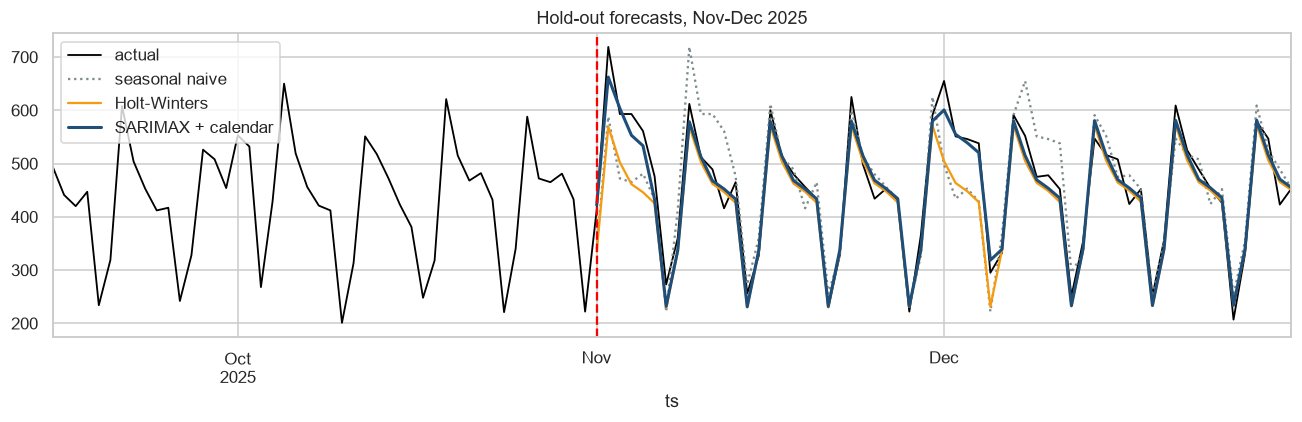

SARIMAX residuals Ljung-Box p (lag 14): 0.7426 -> p > 0.05 means no leftover autocorrelation
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
billing_days    85.8307      3.103     27.661      0.000      79.749      91.912
ramadan         37.4943      5.723      6.552      0.000      26.278      48.710
ar.L1            0.9940      0.009    109.008      0.000       0.976       1.012
ma.L1           -0.8550      0.038    -22.272      0.000      -0.930      -0.780
ar.S.L7         -0.1252      0.064     -1.959      0.050      -0.250    3.27e-05
ma.S.L7         -0.9350      0.039    -23.946      0.000      -1.012      -0.858
sigma2         548.1879     45.011     12.179      0.000     459.967     636.409


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
y["2025-09-15":].plot(ax=ax, color="black", lw=1.2, label="actual")
f_naive.plot(ax=ax, color="#7F8C8D", ls=":", label="seasonal naive"); f_hw.plot(ax=ax, color="#F39C12", label="Holt-Winters")
f_sar.plot(ax=ax, color="#1F4E79", lw=2, label="SARIMAX + calendar")
ax.axvline(pd.Timestamp("2025-11-01"), color="red", ls="--"); ax.legend(); ax.set_title("Hold-out forecasts, Nov-Dec 2025")
plt.tight_layout(); plt.savefig("figures/03_holdout.png"); plt.show()
lb = acorr_ljungbox(sar.resid[7:], lags=[14], return_df=True)
R["ljung_box_p"] = round(float(lb.lb_pvalue.iloc[0]), 4)
print("SARIMAX residuals Ljung-Box p (lag 14):", R["ljung_box_p"], "-> p > 0.05 means no leftover autocorrelation")
print(sar.summary().tables[1])

## 3. Refit on all of 2025 and forecast January and Ramadan 2026
Ramadan 2026 is expected around **18 Feb to 19 Mar 2026** (to be confirmed by moon sighting). The calendar regressors are known in advance, so we can feed them to the model.

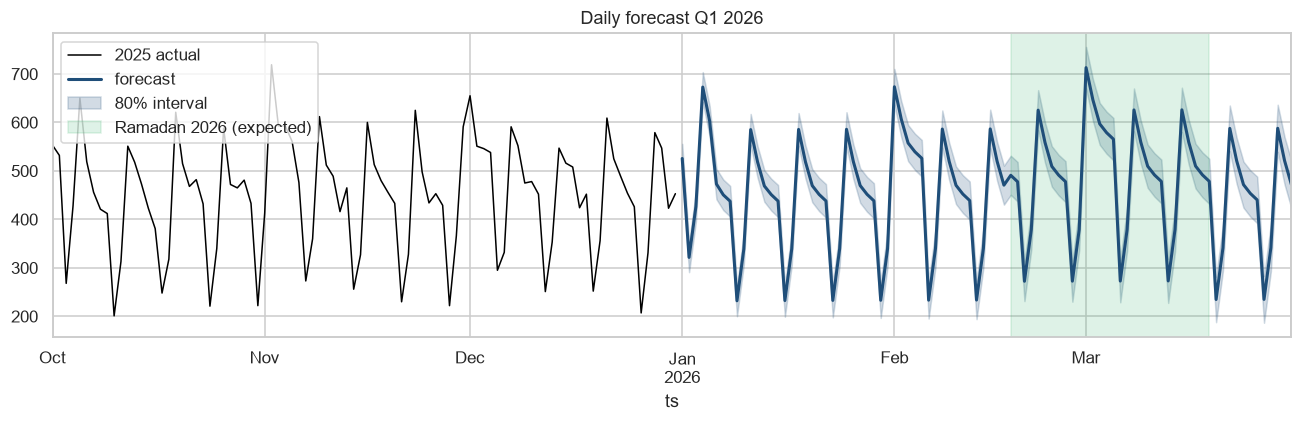

Jan 2026: 13,588 contacts (438/day) | Ramadan 2026 average 489/day


In [6]:
best = SARIMAX(y, exog=cal[["billing_days", "ramadan"]], order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
fut = pd.date_range("2026-01-01", "2026-03-31")
X_f = pd.DataFrame({"billing_days": (fut.day <= 5).astype(int),
                    "ramadan": ((fut >= "2026-02-18") & (fut <= "2026-03-19")).astype(int)}, index=fut)
fc = best.get_forecast(len(fut), exog=X_f)
pred, ci = fc.predicted_mean, fc.conf_int(alpha=0.2)
pred.index = ci.index = fut
R.update(jan26_total=int(pred["2026-01"].sum()), jan26_mean=round(pred["2026-01"].mean(), 1),
         ramadan26_mean=round(pred[X_f.ramadan == 1].mean(), 1), ramadan_coef=round(float(best.params["ramadan"]), 1),
         billing_coef=round(float(best.params["billing_days"]), 1))
fig, ax = plt.subplots(figsize=(12, 4))
y["2025-10-01":].plot(ax=ax, color="black", lw=1, label="2025 actual")
pred.plot(ax=ax, color="#1F4E79", lw=2, label="forecast"); ax.fill_between(fut, ci.iloc[:, 0], ci.iloc[:, 1], color="#1F4E79", alpha=0.2, label="80% interval")
ax.axvspan("2026-02-18", "2026-03-19", color="#27AE60", alpha=0.15, label="Ramadan 2026 (expected)"); ax.legend(); ax.set_title("Daily forecast Q1 2026")
plt.tight_layout(); plt.savefig("figures/04_forecast_q1_2026.png"); plt.show()
print(f"Jan 2026: {R['jan26_total']:,} contacts ({R['jan26_mean']:.0f}/day) | Ramadan 2026 average {R['ramadan26_mean']:.0f}/day")

## 4. From daily volume to hourly staffing (Erlang C)
The daily forecast is split into hours with the 2025 intraday profile (regular days and Ramadan days are profiled separately, because the Ramadan peak moves to the evening).
**Erlang C** gives the probability that a caller waits. From it we get the service level for *N* agents, and we pick the smallest *N* that reaches 80/20. Then we add **30% shrinkage** (breaks, training, absence) to get scheduled agents.

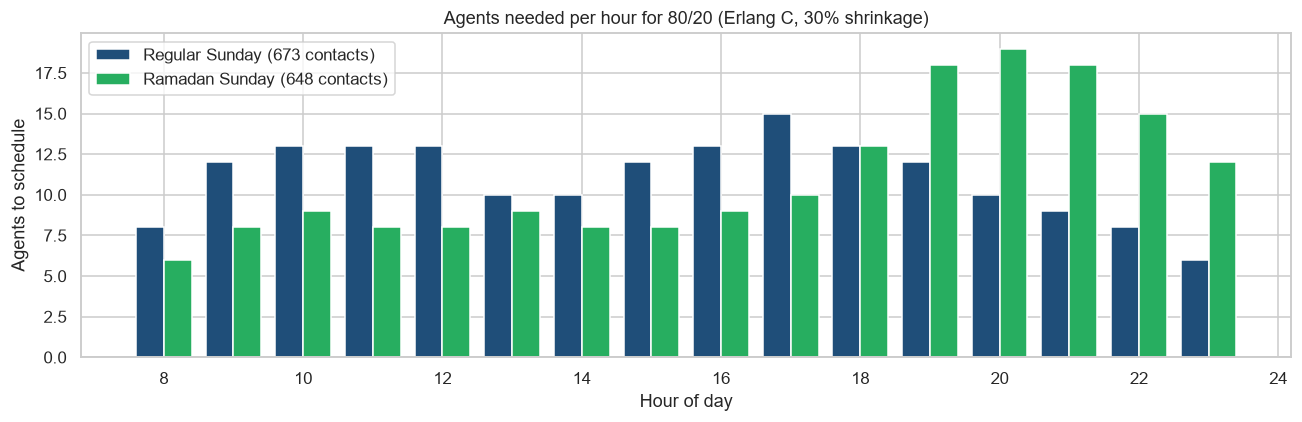

Regular Sunday                                  Ramadan Sunday  \
              calls agents_on_phone agents_scheduled          calls   
hour                                                                  
8              24.5               5                8           15.1   
9              42.9               8               12           21.6   
10             54.5               9               13           27.6   
11             55.2               9               13           26.4   
12             49.3               9               13           25.0   
13             37.2               7               10           28.7   
14             37.6               7               10           21.5   
15             43.7               8               12           20.0   
16             55.5               9               13           28.6   
17             62.2              10               15           35.6   
18             55.6               9               13           56.6   
19             42.6               8               12           75.6   
20             37.6               7               10           82.1   
21             30.8               6                9           75.7   
22             25.0               5                8           62.8   
23             18.8               4                6           44.6   

                                       
     agents_on_phone agents_scheduled  
hour                                   
8                  4                6  
9                  5                8  
10                 6                9  
11                 5                8  
12                 5                8  
13                 6                9  
14                 5                8  
15                 5                8  
16                 6                9  
17                 7               10  
18                 9               13  
19                12               18  
20                13               19  
21                12               18  
22                10               15  
23                 8               12

In [7]:
def erlang_c_sl(calls_per_hour, aht, agents, target_sec=20):
    a = calls_per_hour * aht / 3600                       # offered load in Erlangs
    if agents <= a:
        return 0.0
    s = sum(a ** k / math.factorial(k) for k in range(agents))
    top = a ** agents / math.factorial(agents) * agents / (agents - a)
    pw = top / (s + top)                                   # probability of waiting
    return 1 - pw * math.exp(-(agents - a) * target_sec / aht)

def agents_needed(calls_per_hour, aht, target=0.8, shrinkage=0.30):
    n = max(1, math.ceil(calls_per_hour * aht / 3600))
    while erlang_c_sl(calls_per_hour, aht, n) < target:
        n += 1
    return n, math.ceil(n / (1 - shrinkage))

aht = float(calls[calls.Outcome != "Abandoned"].Handle.mean())
calls["hour"] = calls.ts.dt.hour
calls["is_ram"] = calls.ts.between("2025-03-01", "2025-03-30")
prof = calls.groupby(["is_ram", "hour"]).size() / calls.groupby("is_ram").size()
R["aht_sec"] = round(aht, 1)
def staffing(day_volume, ramadan):
    p = prof.loc[ramadan]
    rows = [[h, day_volume * share, *agents_needed(day_volume * share, aht)] for h, share in p.items()]
    return pd.DataFrame(rows, columns=["hour", "calls", "agents_on_phone", "agents_scheduled"]).set_index("hour")
sun = pred["2026-01-04"]                                    # a regular Sunday in Jan 2026
ram = pred[(X_f.ramadan == 1) & (fut.dayofweek == 6)].mean()  # an average Ramadan Sunday
st_sun, st_ram = staffing(sun, False), staffing(ram, True)
R.update(sunday_volume=round(sun, 1), sunday_peak_scheduled=int(st_sun.agents_scheduled.max()), sunday_agent_hours=int(st_sun.agents_scheduled.sum()),
         ramadan_sunday_volume=round(ram, 1), ramadan_peak_scheduled=int(st_ram.agents_scheduled.max()),
         ramadan_peak_hour=int(st_ram.agents_scheduled.idxmax()), regular_peak_hour=int(st_sun.agents_scheduled.idxmax()))
fig, ax = plt.subplots(figsize=(12, 4))
w = 0.4
ax.bar(st_sun.index - w / 2, st_sun.agents_scheduled, w, label=f"Regular Sunday ({sun:.0f} contacts)", color="#1F4E79")
ax.bar(st_ram.index + w / 2, st_ram.agents_scheduled, w, label=f"Ramadan Sunday ({ram:.0f} contacts)", color="#27AE60")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Agents to schedule"); ax.set_title("Agents needed per hour for 80/20 (Erlang C, 30% shrinkage)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/05_staffing.png"); plt.show()
pd.concat({"Regular Sunday": st_sun, "Ramadan Sunday": st_ram}, axis=1).round(1)

In [8]:
with open("results.json", "w") as f:
    json.dump(R, f, indent=1, default=float)
print(json.dumps({k: R[k] for k in ["jan26_total", "ramadan26_mean", "sunday_peak_scheduled", "ramadan_peak_scheduled", "ramadan_peak_hour"]}, indent=1))

{
 "jan26_total": 13588,
 "ramadan26_mean": 489.0,
 "sunday_peak_scheduled": 15,
 "ramadan_peak_scheduled": 19,
 "ramadan_peak_hour": 20
}


### Recommendations
* **Plan with SARIMAX + calendar regressors.** It beats the seasonal-naive benchmark on the hold-out period, and its residuals show no leftover pattern.
* **Staff by weekday, not by an average day.** Sundays and the first five days of each month need extra agents.
* **Redesign Ramadan shifts.** The peak moves to the late evening, so build evening-heavy rosters for 18 Feb to 19 Mar 2026.
* Refresh the forecast monthly and track the forecast error (MAPE) as a KPI.
* *Caveats:* only one year of history (one Ramadan), so the Ramadan effect is estimated from a single occurrence. Erlang C assumes callers never hang up, so it slightly overstates the agents needed.